# 澳门街道基础对比分析

在 PyCharm 中打开本 Notebook，选择项目的 Python/Jupyter 内核，按顺序运行所有单元格。

使用 **Pandas、NumPy、Matplotlib、Seaborn** 统计和制图，使用 **Shapely、PyProj** 完成区域初分。

统计对象为独立道路要素。道路等级采用源 `fclass`；区域为澳门半岛、氹仔、路氹、路环；功能部分采用普通道路、桥梁、隧道三种**结构类型**。

**口径**：原始长度单位未确认，不能换算公里；`maxspeed=0` 单列待释义，不参与非零均值。没有照片的采样点属于正常情况。区域边界使用已有 OSM 多边形，原始点暂按 WGS84 解释。

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from shapely.geometry import shape, Point
from shapely.ops import unary_union, transform
from pyproj import Transformer
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
available_fonts = {f.name for f in fm.fontManager.ttflist}
chinese_font = next((f for f in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC"] if f in available_fonts), "DejaVu Sans")
plt.rcParams.update({"font.family": chinese_font, "axes.unicode_minus": False, "figure.dpi": 110})
print("Python:", sys.executable)
print("中文字体:", chinese_font)
display(pd.Series({p: importlib.metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "seaborn", "shapely", "pyproj"]}, name="版本"))

Python: C:\Users\25142\anaconda3\python.exe
中文字体: Microsoft YaHei


pandas         2.3.2
numpy         1.26.4
matplotlib    3.10.5
seaborn       0.13.2
shapely        2.1.2
pyproj         3.7.2
Name: 版本, dtype: object

## 1. 读取原始结构化表

自动从 Notebook 当前目录向上定位项目，不依赖临时文件夹。计算与图像写入独立的 `outputs/notebook_analysis/`。

In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "outputs/structured_data_v1/tables/roads.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("请从毕业设计项目目录或 notebooks 子目录运行。")
TABLES = ROOT / "outputs/structured_data_v1/tables"
BOUNDARY_DIR = ROOT / "outputs/basic_street_comparison_v1"
OUT = ROOT / "outputs/notebook_analysis"
OUT.mkdir(parents=True, exist_ok=True)
roads = pd.read_csv(TABLES / "roads.csv", encoding="utf-8-sig", dtype={"road_id": "string", "osm_id": "string"})
points = pd.read_csv(TABLES / "sampling_points.csv", encoding="utf-8-sig")
images = pd.read_csv(TABLES / "images.csv", encoding="utf-8-sig")
assert roads.road_id.is_unique and points.sample_id.is_unique and images.image_id.is_unique
assert points.road_id.isin(roads.road_id).all()
display(pd.DataFrame({"数据": ["独立道路要素", "采样点", "实际图片"], "数量": [len(roads), len(points), len(images)]}))
display(roads.head())

,数据,数量
0,独立道路要素,1537
1,采样点,6879
2,实际图片,5920


,road_id,source_orig_fid,osm_id,code,fclass,name,ref,oneway,maxspeed,layer,bridge,tunnel,shape_length,sample_count,image_count
0,MC-R00001,1,22988070,5114,secondary,嘉樂庇總督大橋 Ponte Governador Nobre de Carvalho,NaN,B,60,2,T,F,0.022515,77,2
1,MC-R00002,2,22988092,5114,secondary,水坑尾街 Rua do Campo,NaN,B,0,0,F,F,0.000740,2,2
2,MC-R00006,6,41888516,5113,primary,友誼大橋 Ponte da Amizade,NaN,F,60,1,T,F,0.007150,24,24
3,MC-R00007,7,41895335,5114,secondary,殷皇子大馬路 Avenida do Infante D. Henrique,NaN,F,0,0,F,F,0.001540,5,5
4,MC-R00009,9,41895759,5113,primary,友誼大馬路 Avenida da Amizade,NaN,F,0,0,F,F,0.001136,3,3


## 2. 四区域空间关联

边界来源和获取日期显示如下。半岛由五堂区合并；氹仔、路氹、路环使用各自 OSM 区域多边形。此处重新计算逐点归属，不直接读取之前的统计结果。

道路超过半数采样点落入同一区域时整条归区，否则列为“未归区/跨区”。区域统计的长度、采样点数和图片数随道路整条归组；它们不表示按行政边界裁切后的长度或点数。边界外点不做最近区域吸附，距边界 30 米以内标记复核。

In [3]:
boundary_data = json.loads((BOUNDARY_DIR / "region_boundaries.geojson").read_text(encoding="utf-8"))
source_info = json.loads((BOUNDARY_DIR / "boundary_sources.json").read_text(encoding="utf-8"))
display(pd.DataFrame(source_info["regions"]).T)
print("边界获取日期:", source_info["retrieved_date"])
regions = {f["properties"]["region"]: shape(f["geometry"]) for f in boundary_data["features"]}
assert all(g.is_valid for g in regions.values())
to_m = Transformer.from_crs(4326, 32649, always_xy=True).transform
borders = unary_union([transform(to_m, g).boundary for g in regions.values()])
NEAR_BOUNDARY_M = 30  # 研究筛查阈值，可调整后重新运行后续单元格

def locate_point(lon, lat):
    p = Point(lon, lat)
    hits = [name for name, geom in regions.items() if geom.covers(p)]
    name = hits[0] if len(hits) == 1 else "未归区/边界"
    distance = transform(to_m, p).distance(borders)
    review = len(hits) != 1 or distance <= NEAR_BOUNDARY_M
    return name, distance, review

located = [locate_point(x, y) for x, y in points[["longitude", "latitude"]].itertuples(index=False, name=None)]
points[["point_region", "boundary_distance_m", "near_boundary_or_outside"]] = pd.DataFrame(located, index=points.index)
assignments = []
for road_id, group in points.groupby("road_id", sort=False):
    counts = group.point_region.value_counts()
    winner = counts.index[0]
    region = winner if counts.iloc[0] > len(group) / 2 and winner != "未归区/边界" else "未归区/跨区"
    assignments.append({"road_id": road_id, "region": region,
                        "region_review": len(counts) > 1 or group.near_boundary_or_outside.any()})
roads = roads.drop(columns=["region", "region_review"], errors="ignore").merge(pd.DataFrame(assignments), on="road_id", validate="one_to_one")
display(roads.region.value_counts().rename_axis("区域初分").to_frame("道路要素数"))

,name,url
fatima,"花地瑪堂區 Nossa Senhora de Fátima, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/9506156
antonio,"花王堂區 Santo António, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/9506168
lazaro,"望德堂區 São Lázaro, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/12107628
lourenco,"風順堂區 São Lourenço, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/12107629
se,"大堂區 Sé, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/12107627
taipa,"氹仔 Taipa, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/5758868
cotai,"路氹填海區 Zona do Aterro de Cotai, 澳門 Macau, 99907...",https://www.openstreetmap.org/relation/5758867
coloane,"路環 Coloane, 澳門 Macau, 中国",https://www.openstreetmap.org/relation/5758869


边界获取日期: 2026-10-19


,道路要素数
区域初分,
澳门半岛,834
氹仔,325
路氹,215
路环,87
未归区/跨区,76


## 3. 结构类型与限速处理

`bridge=T` 标为桥梁，`tunnel=T` 标为隧道，其余为普通道路。限速非零值单独生成分析列，原始字段保留。长度仍为 `Shape_Length` 原始量纲，物理长度待元数据确认。

In [4]:
assert not ((roads.bridge == "T") & (roads.tunnel == "T")).any(), "存在桥隧双重标记，应先核查"
roads["structure"] = np.select([roads.bridge.eq("T"), roads.tunnel.eq("T")], ["桥梁", "隧道"], default="普通道路")
roads["speed_positive"] = roads.maxspeed.where(roads.maxspeed > 0)
roads["speed_is_zero"] = roads.maxspeed.eq(0)
CLASS_ORDER = ["primary", "secondary", "tertiary"]
REGION_ORDER = ["澳门半岛", "氹仔", "路氹", "路环", "未归区/跨区"]
STRUCTURE_ORDER = ["普通道路", "桥梁", "隧道"]

def summarize(column, order):
    result = roads.groupby(column).agg(
        道路要素数=("road_id", "size"), 采样点数=("sample_count", "sum"), 图片数=("image_count", "sum"),
        原始长度合计=("shape_length", "sum"), 非零限速条数=("speed_positive", "count"),
        限速为零条数=("speed_is_zero", "sum"), 非零限速均值=("speed_positive", "mean"),
        非零限速中位数=("speed_positive", "median"), 区域需复核数=("region_review", "sum")
    ).reindex(order)
    result["非零限速填报占比"] = result["非零限速条数"] / result["道路要素数"]
    return result

by_class = summarize("fclass", CLASS_ORDER)
by_region = summarize("region", REGION_ORDER)
by_structure = summarize("structure", STRUCTURE_ORDER)
for title, table in [("道路等级", by_class), ("区域初分", by_region), ("结构类型", by_structure)]:
    display(Markdown(f"### {title}"))
    display(table.round(4))

### 道路等级

,道路要素数,采样点数,图片数,原始长度合计,非零限速条数,限速为零条数,非零限速均值,非零限速中位数,区域需复核数,非零限速填报占比
fclass,,,,,,,,,,
primary,830,3800,3193,1.2154,107,723,57.4766,60.0,145,0.1289
secondary,348,1647,1325,0.5262,31,317,51.9355,60.0,39,0.0891
tertiary,359,1432,1402,0.4685,17,342,45.8824,40.0,10,0.0474


### 区域初分

,道路要素数,采样点数,图片数,原始长度合计,非零限速条数,限速为零条数,非零限速均值,非零限速中位数,区域需复核数,非零限速填报占比
region,,,,,,,,,,
澳门半岛,834,2937,2805,0.9681,61,773,51.8033,60.0,9,0.0731
氹仔,325,1504,1450,0.4804,44,281,57.2727,60.0,47,0.1354
路氹,215,1105,977,0.3496,13,202,50.7692,50.0,51,0.0605
路环,87,579,521,0.1804,19,68,50.5263,50.0,11,0.2184
未归区/跨区,76,754,167,0.2317,18,58,68.8889,80.0,76,0.2368


### 结构类型

,道路要素数,采样点数,图片数,原始长度合计,非零限速条数,限速为零条数,非零限速均值,非零限速中位数,区域需复核数,非零限速填报占比
structure,,,,,,,,,,
普通道路,1434,5581,5118,1.8158,94,1340,53.7234,60.0,149,0.0656
桥梁,77,1072,635,0.3244,48,29,59.1667,60.0,37,0.6234
隧道,26,226,167,0.0699,13,13,50.0000,50.0,8,0.5000


## 4. Matplotlib：数量与原始长度对比

每个面板独立标注指标和量纲。区域中的未归区/跨区道路保留在图中。

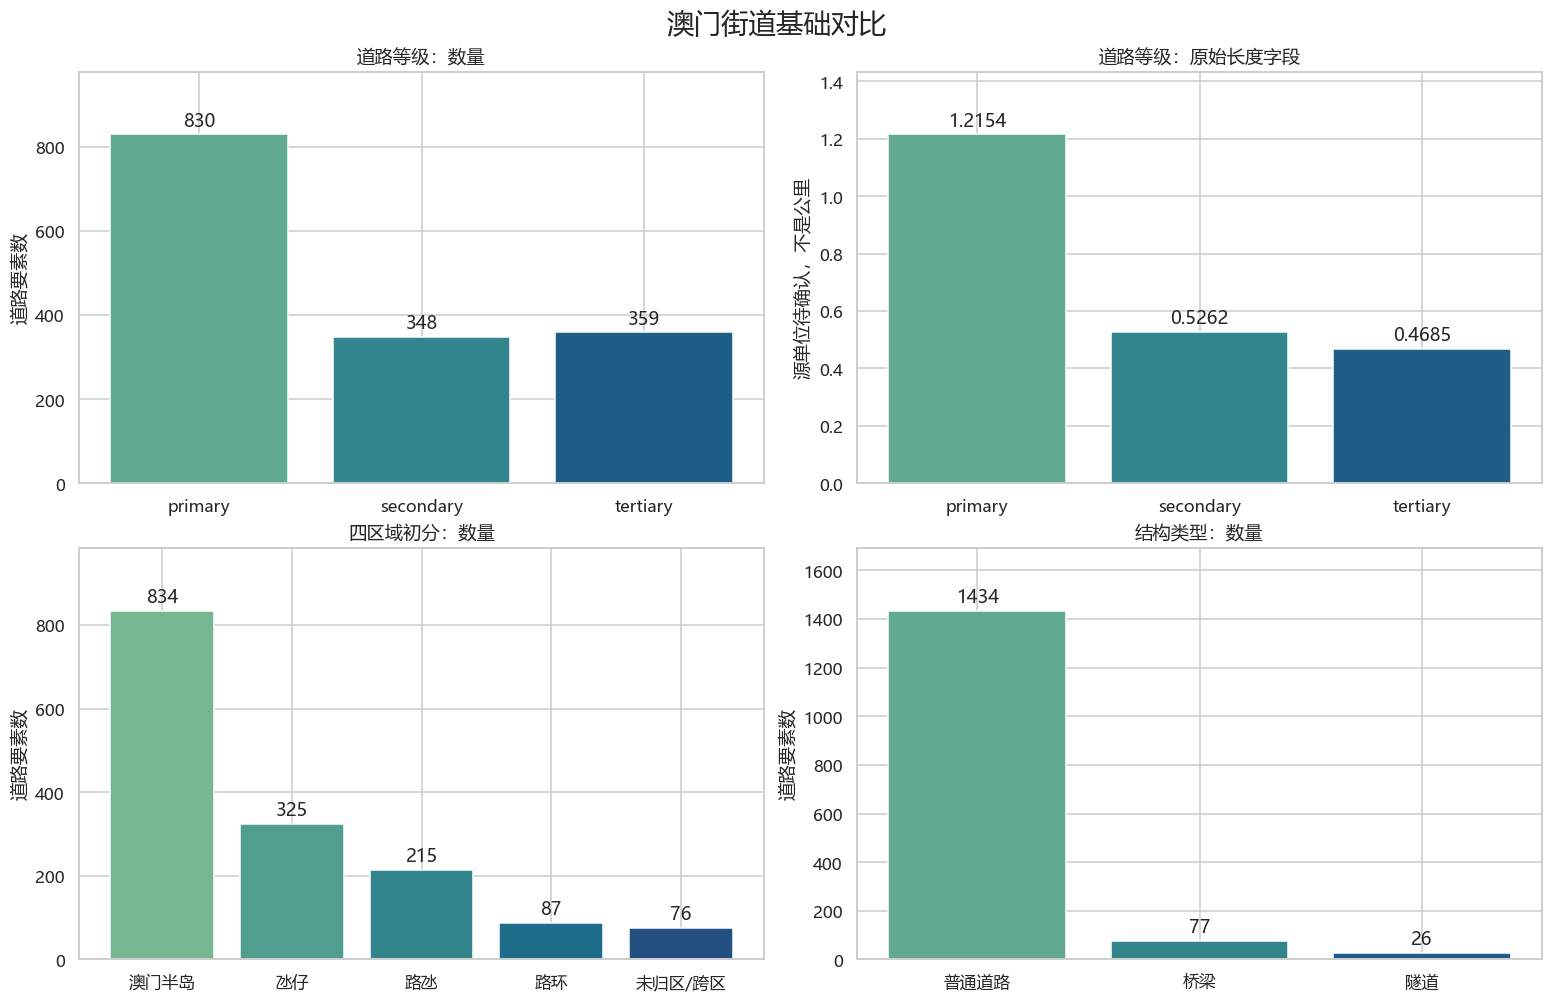

In [5]:
def save_show(fig, filename):
    fig.savefig(OUT / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
panels = [(by_class, "道路要素数", "道路等级：数量", "道路要素数"),
          (by_class, "原始长度合计", "道路等级：原始长度字段", "源单位待确认，不是公里"),
          (by_region, "道路要素数", "四区域初分：数量", "道路要素数"),
          (by_structure, "道路要素数", "结构类型：数量", "道路要素数")]
for ax, (table, metric, title, unit) in zip(axes.flat, panels):
    bars = ax.bar(table.index, table[metric], color=sns.color_palette("crest", len(table)))
    ax.bar_label(bars, fmt="%.4f" if metric == "原始长度合计" else "%.0f", padding=3)
    ax.set(title=title, ylabel=unit)
    ax.margins(y=.18)
fig.suptitle("澳门街道基础对比", fontsize=18)
save_show(fig, "01_数量与长度字段.png")

## 5. Seaborn：限速分布与填报占比

限速图使用源字段值，单位未确认。每类非零值样本量同时展示，防止把少量填报道路的均值外推到全体道路。不绘制推断性置信区间。

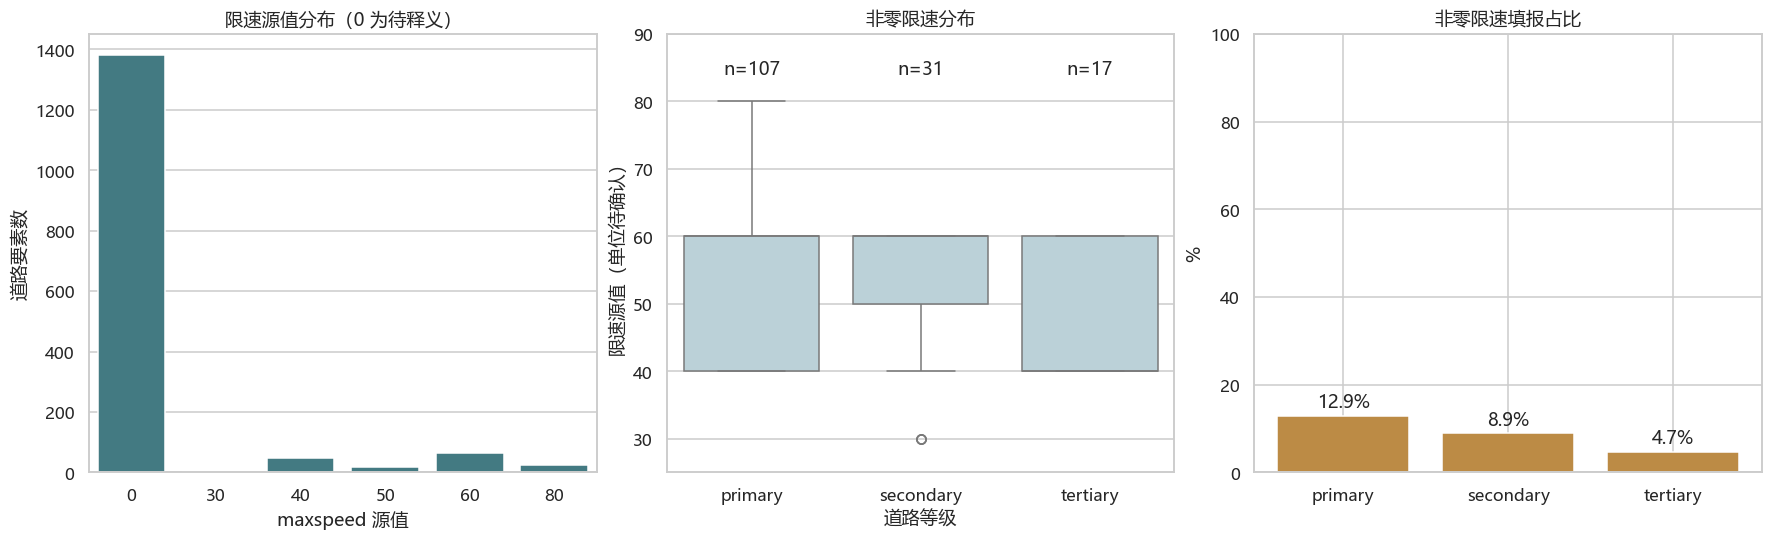

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
sns.countplot(data=roads, x="maxspeed", order=sorted(roads.maxspeed.unique()), color="#39828C", ax=axes[0])
axes[0].set(title="限速源值分布（0 为待释义）", xlabel="maxspeed 源值", ylabel="道路要素数")
sns.boxplot(data=roads.loc[roads.speed_positive.notna()], x="fclass", y="speed_positive", order=CLASS_ORDER, color="#B6D4DD", ax=axes[1])
axes[1].set(title="非零限速分布", xlabel="道路等级", ylabel="限速源值（单位待确认）")
for i, group in enumerate(CLASS_ORDER):
    axes[1].text(i, 84, f'n={int(by_class.loc[group, "非零限速条数"])}', ha="center")
axes[1].set_ylim(25, 90)
bars = axes[2].bar(CLASS_ORDER, by_class["非零限速填报占比"] * 100, color="#BC8B45")
axes[2].bar_label(bars, fmt="%.1f%%", padding=3)
axes[2].set(title="非零限速填报占比", ylabel="%", ylim=(0, 100))
save_show(fig, "02_限速分布与填报.png")

## 6. Seaborn：区域与等级交叉对比

左图为要素数；右图为各区域内部的等级构成，行合计为 100%。不将要素数量解释为路网密度。

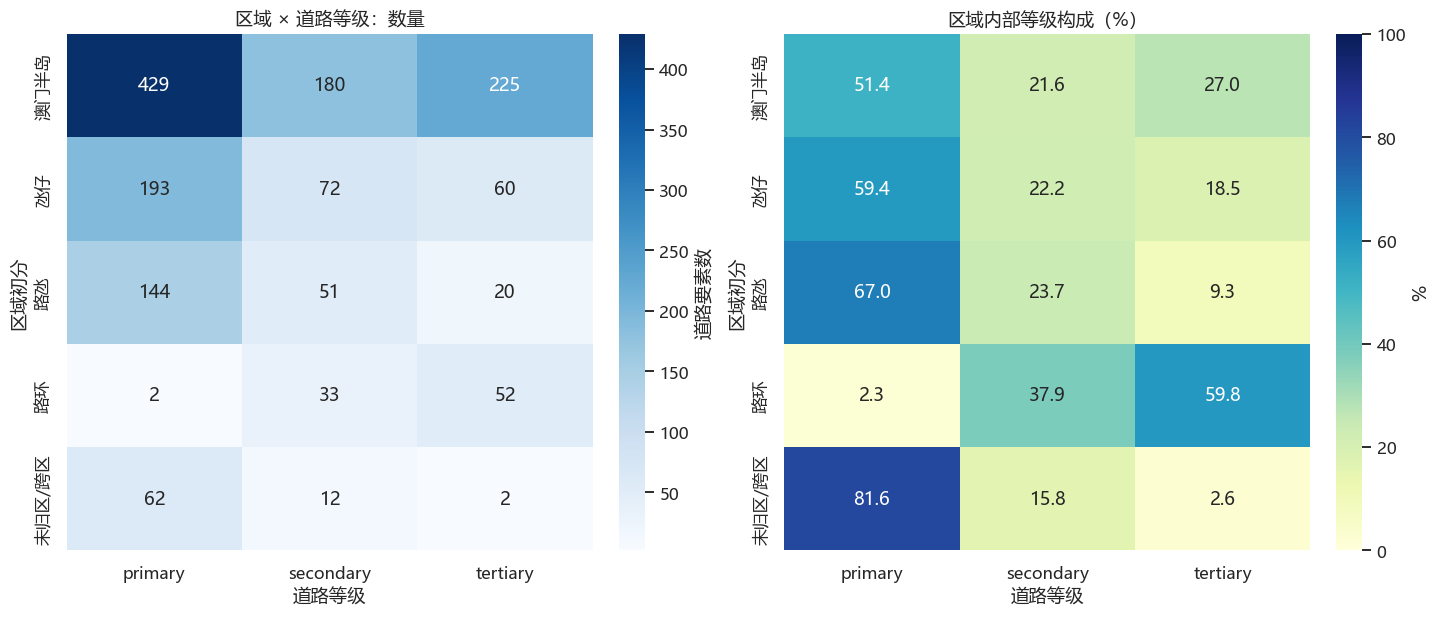

In [7]:
cross = pd.crosstab(roads.region, roads.fclass).reindex(index=REGION_ORDER, columns=CLASS_ORDER, fill_value=0)
composition = cross.div(cross.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "道路要素数"})
sns.heatmap(composition, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "%"})
axes[0].set_title("区域 × 道路等级：数量")
axes[1].set_title("区域内部等级构成（%）")
for ax in axes: ax.set(xlabel="道路等级", ylabel="区域初分")
save_show(fig, "03_区域等级热力图.png")

## 7. Matplotlib：四区域边界与采样点

此图按每个采样点的位置着色，与整条道路多数归属的统计口径不同。边界来源为 © OpenStreetMap contributors（ODbL），原始点坐标系仍待确认。

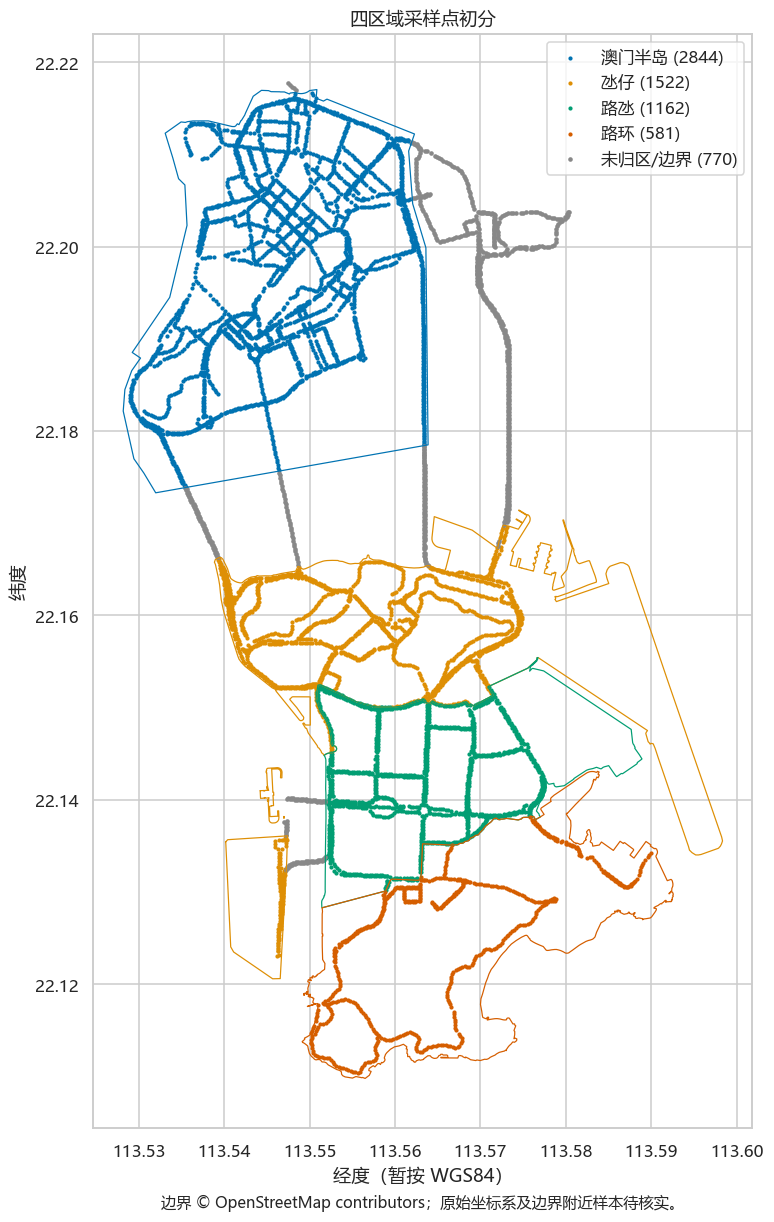

In [8]:
palette = dict(zip(REGION_ORDER[:4], sns.color_palette("colorblind", 4)))
fig, ax = plt.subplots(figsize=(9, 11), layout="constrained")
for name, geom in regions.items():
    for part in (geom.geoms if hasattr(geom, "geoms") else [geom]):
        x, y = part.exterior.xy
        ax.plot(x, y, color=palette[name], linewidth=.8)
    subset = points.loc[points.point_region.eq(name)]
    ax.scatter(subset.longitude, subset.latitude, s=3, color=palette[name], label=f"{name} ({len(subset)})")
outside = points.loc[points.point_region.eq("未归区/边界")]
ax.scatter(outside.longitude, outside.latitude, s=4, c="#888888", label=f"未归区/边界 ({len(outside)})")
ax.set(title="四区域采样点初分", xlabel="经度（暂按 WGS84）", ylabel="纬度", aspect=1 / np.cos(np.deg2rad(points.latitude.mean())))
ax.ticklabel_format(axis="both", style="plain", useOffset=False)
ax.legend(loc="upper right")
fig.supxlabel("边界 © OpenStreetMap contributors；原始坐标系及边界附近样本待核实。", fontsize=10)
save_show(fig, "04_四区域采样点.png")

## 8. 核对、导出与初步发现

核对每个分组维度的总数与源表相等；不会因区域未归属而漏掉道路。运行本节后可以直接在输出目录取用图像与统计表。

In [9]:
for table in [by_class, by_region, by_structure]:
    assert table["道路要素数"].sum() == len(roads)
    assert table["采样点数"].sum() == len(points)
    assert table["图片数"].sum() == len(images)
    assert np.isclose(table["原始长度合计"].sum(), roads.shape_length.sum())
for name, table in [("道路等级统计", by_class), ("区域统计", by_region), ("结构类型统计", by_structure), ("区域等级交叉表", cross)]:
    table.to_csv(OUT / f"{name}.csv", encoding="utf-8-sig")
roads.to_csv(OUT / "道路分析明细.csv", index=False, encoding="utf-8-sig")
points.to_csv(OUT / "采样点区域归属.csv", index=False, encoding="utf-8-sig")
roads.loc[roads.region_review].to_csv(OUT / "区域复核清单.csv", index=False, encoding="utf-8-sig")
zero_count = int(roads.speed_is_zero.sum())
findings = f"""### 初步发现
- 共 {len(roads):,} 条独立道路要素。primary 占 {by_class.loc['primary', '道路要素数'] / len(roads):.1%}；要素切分方式会影响数量。
- 限速字段为 0 的道路有 {zero_count:,} 条，占 {zero_count / len(roads):.1%}。非零值均值只能描述已填报子集。
- 普通道路、桥梁、隧道分别为 {int(by_structure.loc['普通道路', '道路要素数']):,}、{int(by_structure.loc['桥梁', '道路要素数'])}、{int(by_structure.loc['隧道', '道路要素数'])} 条，这是结构类型。
- 四区域之外保留 {int(by_region.loc['未归区/跨区', '道路要素数'])} 条道路；区域复核清单共 {int(roads.region_review.sum())} 条。
- 物理长度尚不能计算，需补充 Shape_Length 单位或原始道路线几何；本 Notebook 未将源数值转换为公里。
"""
display(Markdown(findings))
(OUT / "初步发现.md").write_text(findings, encoding="utf-8")
print("核对通过。结果目录:", OUT)

### 初步发现
- 共 1,537 条独立道路要素。primary 占 54.0%；要素切分方式会影响数量。
- 限速字段为 0 的道路有 1,382 条，占 89.9%。非零值均值只能描述已填报子集。
- 普通道路、桥梁、隧道分别为 1,434、77、26 条，这是结构类型。
- 四区域之外保留 76 条道路；区域复核清单共 194 条。
- 物理长度尚不能计算，需补充 Shape_Length 单位或原始道路线几何；本 Notebook 未将源数值转换为公里。


核对通过。结果目录: E:\毕业设计\outputs\notebook_analysis
